# Chess Move Prediction with a 5×5 Encoder–Decoder Transformer

Academic deep-learning project using sequence-to-sequence prediction of Black chess moves from White move sequences. Implemented in TensorFlow/Keras. Reproduced measurements are in the `results/` directory. The dataset is not redistributed, and this notebook retains saved outputs from the completed run.


## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import gdown
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tqdm.auto import tqdm

print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


In [2]:
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print("GPU memory growth not changed:", exc)

keras.mixed_precision.set_global_policy("float32")
print("GPU:", gpus)
print("Precision policy:", keras.mixed_precision.global_policy())
if not gpus:
    print("WARNING: No GPU found. In Colab select Runtime > Change runtime type > GPU.")

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Precision policy: <DTypePolicy "float32">


### Persistent experiment storage

When running in Google Colab, mount Google Drive **before** training. All checkpoints, logs, vocabulary and evaluation artifacts will go to a versioned run folder. If you deliberately start a new training experiment, set a different `RUN_NAME` rather than overwriting the earlier one.

In [ ]:
from pathlib import Path
import sys
import json
import pickle

RUN_NAME = "transformer_5x5_v1"
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    RUN_DIR = Path("/content/drive/MyDrive/chess_move_prediction") / RUN_NAME
else:
    RUN_DIR = Path.cwd() / "chess_runs" / RUN_NAME

WEIGHTS_DIR = RUN_DIR / "weights"
RESULTS_DIR = RUN_DIR / "results"
ARTIFACTS_DIR = RUN_DIR / "artifacts"
BACKUP_DIR = RUN_DIR / "training_backup"
for folder in (RUN_DIR, WEIGHTS_DIR, RESULTS_DIR, ARTIFACTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

BEST_WEIGHTS_PATH = str(WEIGHTS_DIR / "white_to_black_5x5_best.weights.h5")
TRAIN_LOG_PATH = RESULTS_DIR / "training_history.csv"
VOCAB_PATH = ARTIFACTS_DIR / "joint_vocabulary.json"
CONFIG_PATH = ARTIFACTS_DIR / "model_config.json"

print("Run directory:", RUN_DIR)
print("Best weights:", BEST_WEIGHTS_PATH)

## Dataset access

The input CSV files were supplied for coursework. They are not included in this public repository. For an authorized rerun, place `white_to_black_train.csv` and `white_to_black_test.csv` in the working directory before executing the data-loading cell. See the README for expected column names.


In [ ]:
from pathlib import Path

# Authorized dataset files are intentionally NOT downloaded by this public notebook.
# Place them in the working directory before running the data-loading cell.
required = [Path("white_to_black_train.csv"), Path("white_to_black_test.csv")]
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Required course dataset files not found: " + ", ".join(missing) +
        ". Obtain them through the original authorized course source."
    )
print("Authorized dataset files found.")


## Data loading and preprocessing

Each game is represented by two whitespace-separated strings of White and Black moves, respectively.


In [5]:
TRAIN_PATH = "white_to_black_train.csv"
TEST_PATH = "white_to_black_test.csv"

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

assert set(train_df.columns) == {"white", "black"}
assert set(test_df.columns) == {"white", "black"}

raw_train_count = len(train_df)
raw_test_count = len(test_df)
train_df = train_df.dropna().astype(str)
test_df = test_df.dropna().astype(str)

train_df["white_len"] = train_df["white"].str.split().str.len()
train_df["black_len"] = train_df["black"].str.split().str.len()
test_df["white_len"] = test_df["white"].str.split().str.len()
test_df["black_len"] = test_df["black"].str.split().str.len()

train_df = train_df[train_df["white_len"] == train_df["black_len"]].copy()
test_df = test_df[test_df["white_len"] == test_df["black_len"]].copy()

print("Train:", train_df.shape)
print("Held-out test:", test_df.shape)

train_df.head()

excluded_test_games = raw_test_count - len(test_df)
if excluded_test_games:
    print(f"WARNING: {excluded_test_games} test rows were excluded by the original preprocessing. "
          "Do not call this a full-test result without revising that filter.")


Train: (101364, 4)
Held-out test: (17888, 4)


The training set used in the recorded experiment contained 101,364 games, and the independent test set contained 17,888 games.


## Task formulation

At prediction time, the complete sequence of White moves is known. Black moves are predicted autoregressively. During training, teacher forcing supplies previous ground-truth Black moves; during inference, the model uses only its previous predictions. No chess engine, board state or external opening book is used.


## 5. Compliant experimental protocol and validation split

The solution below uses only the two move strings contained in the provided training file. It does not use chess rules, board states, legal-move generators, opening databases, pretrained chess models, data augmentation, or additional games.

The provided test file is kept untouched until the final evaluation. A deterministic, duplicate-safe validation split is created from the provided training set. Exact duplicate games are assigned to the same side of the split, preventing leakage between training and validation.


In [6]:
SEED = 42
keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

# Deterministic approximately 90/10 split of the provided training set.
# Hashing both columns keeps exact duplicate games in the same partition.
pair_hash = pd.util.hash_pandas_object(
    train_df[["white", "black"]].astype(str),
    index=False,
).to_numpy(dtype=np.uint64)

validation_mask = (pair_hash % np.uint64(10)) == 0

fit_df = train_df.loc[~validation_mask].reset_index(drop=True)
valid_df = train_df.loc[validation_mask].reset_index(drop=True)

fit_hashes = set(pair_hash[~validation_mask].tolist())
valid_hashes = set(pair_hash[validation_mask].tolist())

assert len(fit_df) > 0 and len(valid_df) > 0
assert fit_hashes.isdisjoint(valid_hashes)
assert len(fit_df) + len(valid_df) == len(train_df)

print("Training split:", fit_df.shape)
print("Validation split:", valid_df.shape)
print("Held-out test set:", test_df.shape)


Training split: (91242, 4)
Validation split: (10122, 4)
Held-out test set: (17888, 4)


## 6. Leakage-free shared vectorization

A shared vocabulary is learned only from the new training split. Sharing the token embedding between encoder, decoder, and output projection saves parameters and leaves more capacity for sequence modelling. `[BOS]` is a generic sequence-start token used for teacher forcing; it does not encode chess knowledge.

The complete White sequence is available at test time, so the encoder may attend bidirectionally over that sequence. During training the decoder receives previous true Black tokens; during inference it receives only its own previous predictions, as required by the assignment.


In [7]:
MAX_LEN = 60

def identity_standardize(x):
    return x

BOS_TOKEN = "[BOS]"
JOINT_VOCAB_LIMIT = 10000
TOKENIZE_BATCH_SIZE = 2048

joint_vectorizer = layers.TextVectorization(
    max_tokens=JOINT_VOCAB_LIMIT,
    standardize=identity_standardize,
    split="whitespace",
    output_mode="int",
    output_sequence_length=MAX_LEN,
)

adapt_ds = tf.data.Dataset.from_tensor_slices(
    fit_df["white"].astype(str).to_numpy()
)
adapt_ds = adapt_ds.concatenate(
    tf.data.Dataset.from_tensor_slices(fit_df["black"].astype(str).to_numpy())
)
adapt_ds = adapt_ds.concatenate(tf.data.Dataset.from_tensors(BOS_TOKEN))
joint_vectorizer.adapt(adapt_ds.batch(TOKENIZE_BATCH_SIZE))

joint_vocab = [str(token) for token in joint_vectorizer.get_vocabulary()]
VOCAB_SIZE = len(joint_vocab)
PAD_ID = 0
UNK_ID = 1
BOS_ID = joint_vocab.index(BOS_TOKEN)

# Preserve compatibility with the professor's later inspection utility.
white_vectorizer = joint_vectorizer
black_vectorizer = joint_vectorizer

def vectorize_series(series, batch_size=TOKENIZE_BATCH_SIZE):
    values = series.astype(str).to_numpy()
    encoded_batches = []

    for start in tqdm(range(0, len(values), batch_size), desc="Tokenizing", leave=False):
        batch = tf.constant(values[start:start + batch_size])
        encoded_batches.append(joint_vectorizer(batch).numpy().astype(np.int32))

    return np.concatenate(encoded_batches, axis=0)

def make_decoder_inputs(target_ids):
    decoder_ids = np.zeros_like(target_ids, dtype=np.int32)
    decoder_ids[:, 0] = BOS_ID
    decoder_ids[:, 1:] = target_ids[:, :-1]
    return decoder_ids

x_fit_ids = vectorize_series(fit_df["white"])
y_fit_ids = vectorize_series(fit_df["black"])
decoder_fit_ids = make_decoder_inputs(y_fit_ids)

x_valid_ids = vectorize_series(valid_df["white"])
y_valid_ids = vectorize_series(valid_df["black"])
decoder_valid_ids = make_decoder_inputs(y_valid_ids)

print("Joint vocabulary:", VOCAB_SIZE)
print("Special IDs:", {"PAD": PAD_ID, "UNK": UNK_ID, "BOS": BOS_ID})
print("Training tensors:", x_fit_ids.shape, decoder_fit_ids.shape, y_fit_ids.shape)
print("Validation tensors:", x_valid_ids.shape, decoder_valid_ids.shape, y_valid_ids.shape)


# Preserve the exact token-to-ID mapping needed to reload this checkpoint.
with VOCAB_PATH.open("w", encoding="utf-8") as file:
    json.dump(joint_vocab, file, ensure_ascii=False, indent=2)
print("Saved vocabulary:", VOCAB_PATH)


Tokenizing:   0%|          | 0/45 [00:00<?, ?it/s]

Tokenizing:   0%|          | 0/45 [00:00<?, ?it/s]

Tokenizing:   0%|          | 0/5 [00:00<?, ?it/s]

Tokenizing:   0%|          | 0/5 [00:00<?, ?it/s]

Joint vocabulary: 6228
Special IDs: {'PAD': 0, 'UNK': 1, 'BOS': 4831}
Training tensors: (91242, 60) (91242, 60) (91242, 60)
Validation tensors: (10122, 60) (10122, 60) (10122, 60)
Saved vocabulary: /content/drive/MyDrive/chess_move_prediction/transformer_5x5_v1/artifacts/joint_vocabulary.json


## 7. Fully compliant data-only baseline

The baseline estimates the most frequent Black token for each pair `(position, White token)` using only the training split. Unseen pairs back off to the most frequent Black token at that position. It has zero trainable parameters and provides a completely compliant reference result on the validation split.


In [8]:
def sequence_metrics_from_ids(y_true, y_pred):
    mask = y_true != PAD_ID
    token_matches = (y_true == y_pred) & mask

    move_accuracy = float(token_matches.sum() / np.maximum(mask.sum(), 1))
    lengths = mask.sum(axis=1)
    prefixes = np.zeros(len(y_true), dtype=np.int32)

    for i, length in enumerate(lengths):
        length = int(length)
        if length == 0:
            continue

        row_matches = token_matches[i, :length]
        first_error = np.flatnonzero(~row_matches)
        prefixes[i] = int(first_error[0]) if len(first_error) else length

    max_prefix = int(prefixes.max()) if len(prefixes) else 0
    survival = np.array(
        [(prefixes >= k).mean() for k in range(1, max_prefix + 1)],
        dtype=np.float64,
    )

    return {
        "move_accuracy": move_accuracy,
        "mean_prefix": float(prefixes.mean()) if len(prefixes) else 0.0,
        "survival_auc": float(survival.sum()),
        "survival": survival,
        "prefixes": prefixes,
    }

def fit_position_response_baseline(x_ids, y_ids, vocab_size):
    response_map = np.full((MAX_LEN, vocab_size), PAD_ID, dtype=np.int32)

    for position in tqdm(range(MAX_LEN), desc="Fitting compliant baseline"):
        valid = y_ids[:, position] != PAD_ID
        if not np.any(valid):
            continue

        white_tokens = x_ids[valid, position]
        black_tokens = y_ids[valid, position]

        default_token = int(
            np.bincount(black_tokens, minlength=vocab_size).argmax()
        )
        response_map[position, :] = default_token

        counts = (
            pd.DataFrame({"white_id": white_tokens, "black_id": black_tokens})
            .groupby(["white_id", "black_id"], sort=False)
            .size()
            .reset_index(name="count")
        )

        best = (
            counts.sort_values(
                ["white_id", "count", "black_id"],
                ascending=[True, False, True],
            )
            .drop_duplicates("white_id")
        )

        response_map[
            position,
            best["white_id"].to_numpy(dtype=np.int32),
        ] = best["black_id"].to_numpy(dtype=np.int32)

    return response_map

baseline_response_map = fit_position_response_baseline(
    x_fit_ids,
    y_fit_ids,
    VOCAB_SIZE,
)

baseline_valid_pred = np.empty_like(y_valid_ids)
for position in range(MAX_LEN):
    baseline_valid_pred[:, position] = baseline_response_map[
        position,
        x_valid_ids[:, position],
    ]

baseline_valid_metrics = sequence_metrics_from_ids(
    y_valid_ids,
    baseline_valid_pred,
)

print("Compliant baseline validation move accuracy:",
      baseline_valid_metrics["move_accuracy"])
print("Compliant baseline validation mean correct prefix:",
      baseline_valid_metrics["mean_prefix"])
print("Compliant baseline validation Survival AUC:",
      baseline_valid_metrics["survival_auc"])


Fitting compliant baseline:   0%|          | 0/60 [00:00<?, ?it/s]

Compliant baseline validation move accuracy: 0.11224824901329734
Compliant baseline validation mean correct prefix: 0.6810906935388263
Compliant baseline validation Survival AUC: 0.6810906935388263


## 8. Proposed model: deeper compact autoregressive Transformer

The main model uses five encoder blocks and five decoder blocks. To remain below the mandatory six-million-parameter limit, the hidden dimension is reduced to 160, with five attention heads of dimension 32 and a feed-forward dimension of 480. The shared token embedding is also tied to the output projection.

The encoder models the complete White sequence. The causal decoder predicts Black moves autoregressively and uses teacher forcing only during training. An aligned gated residual connects each encoded White position directly to the corresponding decoder position.

During inference, the encoder representation is computed once and reused for every autoregressive step and every beam. This substantially reduces decoding cost without changing the model or using external information.

Because Survival AUC is dominated by errors near the beginning of a sequence, the masked training loss gives moderately larger weight to early positions while retaining nonzero weight for every move. This weighting follows only from the supplied metric and does not encode chess knowledge.


In [9]:
D_MODEL = 160
NUM_HEADS = 5
FF_DIM = 480
NUM_ENCODER_BLOCKS = 5
NUM_DECODER_BLOCKS = 5
DROPOUT_RATE = 0.15
TRAIN_BATCH_SIZE = 128

assert D_MODEL % NUM_HEADS == 0


class EncoderBlock(layers.Layer):
    def __init__(self, d_model, num_heads, ff_dim, dropout_rate):
        super().__init__()
        self.norm_1 = layers.LayerNormalization(epsilon=1e-5)
        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=d_model // num_heads,
            dropout=dropout_rate,
        )
        self.dropout_1 = layers.Dropout(dropout_rate)

        self.norm_2 = layers.LayerNormalization(epsilon=1e-5)
        self.ffn = keras.Sequential([
            layers.Dense(ff_dim, activation="gelu"),
            layers.Dropout(dropout_rate),
            layers.Dense(d_model),
        ])
        self.dropout_2 = layers.Dropout(dropout_rate)

    def call(self, x, padding_mask, training=False):
        normalized = self.norm_1(x)
        attention_mask = padding_mask[:, tf.newaxis, :]
        attended = self.attention(
            query=normalized,
            value=normalized,
            key=normalized,
            attention_mask=attention_mask,
            training=training,
        )
        x = x + self.dropout_1(attended, training=training)

        normalized = self.norm_2(x)
        transformed = self.ffn(normalized, training=training)
        return x + self.dropout_2(transformed, training=training)


class DecoderBlock(layers.Layer):
    def __init__(self, d_model, num_heads, ff_dim, dropout_rate):
        super().__init__()
        self.norm_1 = layers.LayerNormalization(epsilon=1e-5)
        self.self_attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=d_model // num_heads,
            dropout=dropout_rate,
        )
        self.dropout_1 = layers.Dropout(dropout_rate)

        self.norm_2 = layers.LayerNormalization(epsilon=1e-5)
        self.cross_attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=d_model // num_heads,
            dropout=dropout_rate,
        )
        self.dropout_2 = layers.Dropout(dropout_rate)

        self.norm_3 = layers.LayerNormalization(epsilon=1e-5)
        self.ffn = keras.Sequential([
            layers.Dense(ff_dim, activation="gelu"),
            layers.Dropout(dropout_rate),
            layers.Dense(d_model),
        ])
        self.dropout_3 = layers.Dropout(dropout_rate)

    def call(
        self,
        x,
        encoder_output,
        decoder_padding_mask,
        encoder_padding_mask,
        training=False,
    ):
        length = tf.shape(x)[1]
        causal_mask = tf.linalg.band_part(
            tf.ones((length, length), dtype=tf.bool),
            -1,
            0,
        )

        self_mask = (
            causal_mask[tf.newaxis, :, :]
            & decoder_padding_mask[:, tf.newaxis, :]
            & decoder_padding_mask[:, :, tf.newaxis]
        )

        normalized = self.norm_1(x)
        attended = self.self_attention(
            query=normalized,
            value=normalized,
            key=normalized,
            attention_mask=self_mask,
            training=training,
        )
        x = x + self.dropout_1(attended, training=training)

        cross_mask = (
            decoder_padding_mask[:, :, tf.newaxis]
            & encoder_padding_mask[:, tf.newaxis, :]
        )

        normalized = self.norm_2(x)
        attended = self.cross_attention(
            query=normalized,
            value=encoder_output,
            key=encoder_output,
            attention_mask=cross_mask,
            training=training,
        )
        x = x + self.dropout_2(attended, training=training)

        normalized = self.norm_3(x)
        transformed = self.ffn(normalized, training=training)
        return x + self.dropout_3(transformed, training=training)


class WhiteToBlackTransformer(keras.Model):
    def __init__(self, vocab_size, max_len):
        super().__init__()
        self.vocab_size = vocab_size
        self.max_len = max_len

        self.token_embedding = layers.Embedding(
            vocab_size,
            D_MODEL,
            name="shared_token_embedding",
        )
        self.encoder_position_embedding = layers.Embedding(max_len, D_MODEL)
        self.decoder_position_embedding = layers.Embedding(max_len, D_MODEL)
        self.embedding_dropout = layers.Dropout(DROPOUT_RATE)

        self.encoder_blocks = [
            EncoderBlock(D_MODEL, NUM_HEADS, FF_DIM, DROPOUT_RATE)
            for _ in range(NUM_ENCODER_BLOCKS)
        ]
        self.decoder_blocks = [
            DecoderBlock(D_MODEL, NUM_HEADS, FF_DIM, DROPOUT_RATE)
            for _ in range(NUM_DECODER_BLOCKS)
        ]

        self.fusion_gate = layers.Dense(1, activation="sigmoid")
        self.fusion_norm = layers.LayerNormalization(epsilon=1e-5)

        # Output matrix is tied to token_embedding; only a bias is added.
        self.output_bias = self.add_weight(
            name="output_bias",
            shape=(vocab_size,),
            initializer="zeros",
            trainable=True,
        )

    def encode(self, encoder_ids, training=False):
        encoder_ids = tf.cast(encoder_ids, tf.int32)
        encoder_mask = tf.not_equal(encoder_ids, PAD_ID)
        positions = tf.range(tf.shape(encoder_ids)[1])

        encoder_output = (
            self.token_embedding(encoder_ids)
            + self.encoder_position_embedding(positions)
        )
        encoder_output = self.embedding_dropout(
            encoder_output,
            training=training,
        )

        for block in self.encoder_blocks:
            encoder_output = block(
                encoder_output,
                encoder_mask,
                training=training,
            )

        encoder_output *= tf.cast(
            encoder_mask[:, :, tf.newaxis],
            encoder_output.dtype,
        )
        return encoder_output, encoder_mask

    def decode_hidden(
        self,
        decoder_ids,
        encoder_output,
        encoder_mask,
        training=False,
    ):
        decoder_ids = tf.cast(decoder_ids, tf.int32)
        decoder_mask = tf.not_equal(decoder_ids, PAD_ID)
        positions = tf.range(tf.shape(decoder_ids)[1])

        decoder_output = (
            self.token_embedding(decoder_ids)
            + self.decoder_position_embedding(positions)
        )
        decoder_output = self.embedding_dropout(
            decoder_output,
            training=training,
        )

        for block in self.decoder_blocks:
            decoder_output = block(
                decoder_output,
                encoder_output,
                decoder_mask,
                encoder_mask,
                training=training,
            )

        aligned_encoder = encoder_output[:, :tf.shape(decoder_output)[1], :]
        gate = self.fusion_gate(
            tf.concat([decoder_output, aligned_encoder], axis=-1)
        )
        fused = self.fusion_norm(
            decoder_output + gate * aligned_encoder
        )
        fused *= tf.cast(
            decoder_mask[:, :, tf.newaxis],
            fused.dtype,
        )
        return fused

    def project(self, hidden_states):
        logits = tf.linalg.matmul(
            hidden_states,
            self.token_embedding.embeddings,
            transpose_b=True,
        )
        logits = logits + tf.cast(self.output_bias, logits.dtype)
        return tf.cast(logits, tf.float32)

    def decode_last_logits(
        self,
        decoder_prefix_ids,
        encoder_output,
        encoder_mask,
    ):
        hidden = self.decode_hidden(
            decoder_prefix_ids,
            encoder_output,
            encoder_mask,
            training=False,
        )
        return self.project(hidden[:, -1, :])

    def call(self, inputs, training=False):
        encoder_ids, decoder_ids = inputs
        encoder_output, encoder_mask = self.encode(
            encoder_ids,
            training=training,
        )
        hidden = self.decode_hidden(
            decoder_ids,
            encoder_output,
            encoder_mask,
            training=training,
        )
        return self.project(hidden)


# Moderate early-position weighting aligns cross-entropy with Survival AUC.
_position_index = np.arange(MAX_LEN, dtype=np.float32)
_position_weights = 1.0 + 2.5 * np.exp(-_position_index / 8.0)
_position_weights /= _position_weights.mean()
POSITION_LOSS_WEIGHTS = tf.constant(_position_weights, dtype=tf.float32)


def masked_sparse_categorical_crossentropy(y_true, y_pred):
    per_token_loss = keras.losses.sparse_categorical_crossentropy(
        y_true,
        y_pred,
        from_logits=True,
    )
    mask = tf.cast(tf.not_equal(y_true, PAD_ID), per_token_loss.dtype)
    position_weights = tf.cast(
        POSITION_LOSS_WEIGHTS[tf.newaxis, :tf.shape(y_true)[1]],
        per_token_loss.dtype,
    )
    weighted_mask = mask * position_weights

    return tf.reduce_sum(per_token_loss * weighted_mask) / tf.maximum(
        tf.reduce_sum(weighted_mask),
        tf.constant(1.0, dtype=weighted_mask.dtype),
    )


class MaskedTokenAccuracy(keras.metrics.Metric):
    def __init__(self, name="masked_token_accuracy", **kwargs):
        super().__init__(name=name, **kwargs)
        self.correct = self.add_weight(name="correct", initializer="zeros")
        self.count = self.add_weight(name="count", initializer="zeros")

    def update_state(self, y_true, y_pred, sample_weight=None):
        predicted = tf.argmax(y_pred, axis=-1, output_type=y_true.dtype)
        mask = tf.not_equal(y_true, PAD_ID)
        matches = tf.equal(y_true, predicted) & mask

        self.correct.assign_add(
            tf.reduce_sum(tf.cast(matches, self.dtype))
        )
        self.count.assign_add(
            tf.reduce_sum(tf.cast(mask, self.dtype))
        )

    def result(self):
        return tf.math.divide_no_nan(self.correct, self.count)

    def reset_state(self):
        self.correct.assign(0.0)
        self.count.assign(0.0)


def build_core_model():
    candidate = WhiteToBlackTransformer(VOCAB_SIZE, MAX_LEN)
    dummy_encoder = tf.zeros((1, MAX_LEN), dtype=tf.int32)
    dummy_decoder = tf.concat([
        tf.fill((1, 1), tf.cast(BOS_ID, tf.int32)),
        tf.zeros((1, MAX_LEN - 1), dtype=tf.int32),
    ], axis=1)
    candidate((dummy_encoder, dummy_decoder), training=False)
    return candidate


core_model = build_core_model()
trainable_parameters = int(np.sum([
    np.prod(variable.shape)
    for variable in core_model.trainable_variables
]))

print("Architecture:", {
    "encoder_blocks": NUM_ENCODER_BLOCKS,
    "decoder_blocks": NUM_DECODER_BLOCKS,
    "attention_heads": NUM_HEADS,
    "head_dimension": D_MODEL // NUM_HEADS,
    "d_model": D_MODEL,
    "ff_dim": FF_DIM,
})
print("Trainable parameters:", f"{trainable_parameters:,}")
assert trainable_parameters < 6_000_000, (
    f"Parameter limit exceeded: {trainable_parameters:,}"
)

# A checkpoint is only meaningful together with its model configuration.
model_config = {
    "run_name": RUN_NAME,
    "max_len": int(MAX_LEN),
    "vocab_size": int(VOCAB_SIZE),
    "d_model": int(D_MODEL),
    "num_heads": int(NUM_HEADS),
    "ff_dim": int(FF_DIM),
    "num_encoder_blocks": int(NUM_ENCODER_BLOCKS),
    "num_decoder_blocks": int(NUM_DECODER_BLOCKS),
    "dropout_rate": float(DROPOUT_RATE),
    "batch_size": int(TRAIN_BATCH_SIZE),
    "seed": int(SEED),
    "trainable_parameters": int(trainable_parameters),
}
with CONFIG_PATH.open("w", encoding="utf-8") as file:
    json.dump(model_config, file, indent=2)
print("Saved model configuration:", CONFIG_PATH)

train_tensor_ds = (
    tf.data.Dataset.from_tensor_slices(
        ((x_fit_ids, decoder_fit_ids), y_fit_ids)
    )
    .shuffle(
        buffer_size=min(len(x_fit_ids), 20000),
        seed=SEED,
        reshuffle_each_iteration=True,
    )
    .batch(TRAIN_BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

valid_tensor_ds = (
    tf.data.Dataset.from_tensor_slices(
        ((x_valid_ids, decoder_valid_ids), y_valid_ids)
    )
    .batch(TRAIN_BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


Architecture: {'encoder_blocks': 5, 'decoder_blocks': 5, 'attention_heads': 5, 'head_dimension': 32, 'd_model': 160, 'ff_dim': 480}
Trainable parameters: 4,118,549
Saved model configuration: /content/drive/MyDrive/chess_move_prediction/transformer_5x5_v1/artifacts/model_config.json


## 9. Training and model selection

Only the training split updates the model. Validation loss controls early stopping and checkpoint selection. AdamW uses a one-epoch linear warm-up followed by cosine decay, which is more stable for the deeper 5+5 architecture than beginning immediately at the maximum learning rate.


In [10]:
# BEST_WEIGHTS_PATH and TRAIN_LOG_PATH are configured in the persistent storage block.
MAX_EPOCHS = 24
STEPS_PER_EPOCH = int(np.ceil(len(x_fit_ids) / TRAIN_BATCH_SIZE))
TOTAL_TRAINING_STEPS = STEPS_PER_EPOCH * MAX_EPOCHS
WARMUP_STEPS = max(STEPS_PER_EPOCH, 1)


class WarmupCosineDecay(keras.optimizers.schedules.LearningRateSchedule):
    def __init__(
        self,
        peak_learning_rate,
        warmup_steps,
        total_steps,
        minimum_learning_rate,
    ):
        super().__init__()
        self.peak_learning_rate = float(peak_learning_rate)
        self.warmup_steps = int(warmup_steps)
        self.total_steps = int(total_steps)
        self.minimum_learning_rate = float(minimum_learning_rate)

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        warmup_steps = tf.cast(self.warmup_steps, tf.float32)
        total_steps = tf.cast(self.total_steps, tf.float32)

        warmup_rate = self.peak_learning_rate * (
            (step + 1.0) / tf.maximum(warmup_steps, 1.0)
        )

        decay_progress = (
            (step - warmup_steps)
            / tf.maximum(total_steps - warmup_steps, 1.0)
        )
        decay_progress = tf.clip_by_value(decay_progress, 0.0, 1.0)
        cosine = 0.5 * (1.0 + tf.cos(np.pi * decay_progress))
        cosine_rate = (
            self.minimum_learning_rate
            + (self.peak_learning_rate - self.minimum_learning_rate) * cosine
        )

        return tf.where(step < warmup_steps, warmup_rate, cosine_rate)

    def get_config(self):
        return {
            "peak_learning_rate": self.peak_learning_rate,
            "warmup_steps": self.warmup_steps,
            "total_steps": self.total_steps,
            "minimum_learning_rate": self.minimum_learning_rate,
        }


learning_rate = WarmupCosineDecay(
    peak_learning_rate=3e-4,
    warmup_steps=WARMUP_STEPS,
    total_steps=TOTAL_TRAINING_STEPS,
    minimum_learning_rate=2e-5,
)

optimizer = keras.optimizers.AdamW(
    learning_rate=learning_rate,
    weight_decay=1e-4,
    clipnorm=1.0,
)

core_model.compile(
    optimizer=optimizer,
    loss=masked_sparse_categorical_crossentropy,
    metrics=[MaskedTokenAccuracy()],
)

# When resuming an interrupted run, preserve the best validation threshold.
prior_best_val_loss = None
if TRAIN_LOG_PATH.exists():
    previous_log = pd.read_csv(TRAIN_LOG_PATH)
    if "val_loss" in previous_log and not previous_log.empty:
        best_so_far = pd.to_numeric(previous_log["val_loss"], errors="coerce").min()
        if pd.notna(best_so_far):
            prior_best_val_loss = float(best_so_far)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        BEST_WEIGHTS_PATH,
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        initial_value_threshold=prior_best_val_loss,
        verbose=1,
    ),
    keras.callbacks.CSVLogger(
        str(TRAIN_LOG_PATH),
        append=TRAIN_LOG_PATH.exists(),
    ),
    keras.callbacks.BackupAndRestore(
        backup_dir=str(BACKUP_DIR),
        save_freq="epoch",
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=5,
        min_delta=1e-4,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.TerminateOnNaN(),
]

history = core_model.fit(
    train_tensor_ds,
    validation_data=valid_tensor_ds,
    epochs=MAX_EPOCHS,
    callbacks=callbacks,
)

# Explicitly reload the checkpoint selected only through validation loss.
core_model.load_weights(BEST_WEIGHTS_PATH)


print("Best checkpoint on Drive:", BEST_WEIGHTS_PATH)
print("Training CSV on Drive:", TRAIN_LOG_PATH)
if TRAIN_LOG_PATH.exists():
    training_log = pd.read_csv(TRAIN_LOG_PATH)
    print(training_log.tail())


Epoch 19/24
713/713 ━━━━━━━━━━━━━━━━━━━━ 0s 230ms/step - loss: 2.3484 - masked_token_accuracy: 0.3709
Epoch 19: val_loss improved from 2.19193 to 2.18200, saving model to /content/drive/MyDrive/chess_move_prediction/transformer_5x5_v1/weights/white_to_black_5x5_best.weights.h5

Epoch 19: finished saving model to /content/drive/MyDrive/chess_move_prediction/transformer_5x5_v1/weights/white_to_black_5x5_best.weights.h5
713/713 ━━━━━━━━━━━━━━━━━━━━ 270s 261ms/step - loss: 2.3477 - masked_token_accuracy: 0.3709 - val_loss: 2.1820 - val_masked_token_accuracy: 0.4052
Epoch 20/24
713/713 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - loss: 2.3363 - masked_token_accuracy: 0.3730
Epoch 20: val_loss improved from 2.18200 to 2.17468, saving model to /content/drive/MyDrive/chess_move_prediction/transformer_5x5_v1/weights/white_to_black_5x5_best.weights.h5

Epoch 20: finished saving model to /content/drive/MyDrive/chess_move_prediction/transformer_5x5_v1/weights/white_to_black_5x5_best.weights.h5
713/713 ━━━

## 10. Validation-selected autoregressive decoding

Greedy decoding and beam search use only probabilities produced by the trained model. They do not use chess rules or external data. Beam search is vectorized across each batch, and the encoder representation is cached once per game.

Beam width and an optional early-score bias are selected on a deterministic subset of the validation split. Greedy decoding remains an explicit candidate, so beam search is retained only when it improves the supplied Survival AUC. The selected configuration is then evaluated on the complete validation split.


In [11]:
forbidden_logit_mask = np.zeros(VOCAB_SIZE, dtype=np.float32)
forbidden_logit_mask[[PAD_ID, UNK_ID, BOS_ID]] = -1e9
FORBIDDEN_LOGIT_MASK = tf.constant(forbidden_logit_mask)

pad_only_score = np.full(VOCAB_SIZE, -1e9, dtype=np.float32)
pad_only_score[PAD_ID] = 0.0
PAD_ONLY_SCORE = tf.constant(pad_only_score)
NEGATIVE_INFINITY = tf.constant(-1e9, dtype=tf.float32)


@tf.function(
    input_signature=[tf.TensorSpec((None, MAX_LEN), tf.int32)],
    reduce_retracing=True,
)
def greedy_decode_batch(encoder_ids):
    batch_size = tf.shape(encoder_ids)[0]
    encoder_output, encoder_mask = core_model.encode(
        encoder_ids,
        training=False,
    )

    decoder_ids = tf.concat([
        tf.fill((batch_size, 1), tf.cast(BOS_ID, tf.int32)),
        tf.zeros((batch_size, MAX_LEN - 1), dtype=tf.int32),
    ], axis=1)
    predictions = tf.zeros((batch_size, MAX_LEN), dtype=tf.int32)
    sequence_lengths = tf.reduce_sum(
        tf.cast(tf.not_equal(encoder_ids, PAD_ID), tf.int32),
        axis=1,
    )

    step = tf.constant(0, dtype=tf.int32)

    def condition(step, decoder_ids, predictions):
        return step < tf.reduce_max(sequence_lengths)

    def body(step, decoder_ids, predictions):
        decoder_prefix = decoder_ids[:, :step + 1]
        step_logits = core_model.decode_last_logits(
            decoder_prefix,
            encoder_output,
            encoder_mask,
        )
        step_logits = step_logits + FORBIDDEN_LOGIT_MASK[tf.newaxis, :]
        next_id = tf.argmax(step_logits, axis=-1, output_type=tf.int32)

        active = step < sequence_lengths
        next_id = tf.where(active, next_id, tf.cast(PAD_ID, tf.int32))

        prediction_position = tf.one_hot(
            step,
            MAX_LEN,
            dtype=tf.int32,
        )[tf.newaxis, :]
        predictions = (
            predictions * (1 - prediction_position)
            + next_id[:, tf.newaxis] * prediction_position
        )

        def update_decoder():
            decoder_position = tf.one_hot(
                step + 1,
                MAX_LEN,
                dtype=tf.int32,
            )[tf.newaxis, :]
            return (
                decoder_ids * (1 - decoder_position)
                + next_id[:, tf.newaxis] * decoder_position
            )

        decoder_ids = tf.cond(
            step + 1 < MAX_LEN,
            update_decoder,
            lambda: decoder_ids,
        )

        return step + 1, decoder_ids, predictions

    _, _, predictions = tf.while_loop(
        condition,
        body,
        loop_vars=(step, decoder_ids, predictions),
        shape_invariants=(
            step.shape,
            tf.TensorShape([None, MAX_LEN]),
            tf.TensorShape([None, MAX_LEN]),
        ),
        parallel_iterations=1,
        maximum_iterations=MAX_LEN,
    )

    return predictions


def make_beam_decoder(beam_width, early_score_bias):
    beam_width = int(beam_width)
    early_score_bias = float(early_score_bias)

    @tf.function(
        input_signature=[tf.TensorSpec((None, MAX_LEN), tf.int32)],
        reduce_retracing=True,
    )
    def beam_decode_batch(encoder_ids):
        batch_size = tf.shape(encoder_ids)[0]
        sequence_lengths = tf.reduce_sum(
            tf.cast(tf.not_equal(encoder_ids, PAD_ID), tf.int32),
            axis=1,
        )

        encoder_output, encoder_mask = core_model.encode(
            encoder_ids,
            training=False,
        )
        encoder_output = tf.repeat(
            encoder_output[:, tf.newaxis, :, :],
            repeats=beam_width,
            axis=1,
        )
        encoder_mask = tf.repeat(
            encoder_mask[:, tf.newaxis, :],
            repeats=beam_width,
            axis=1,
        )
        encoder_output_flat = tf.reshape(
            encoder_output,
            (-1, MAX_LEN, D_MODEL),
        )
        encoder_mask_flat = tf.reshape(
            encoder_mask,
            (-1, MAX_LEN),
        )

        decoder_ids = tf.concat([
            tf.fill(
                (batch_size, beam_width, 1),
                tf.cast(BOS_ID, tf.int32),
            ),
            tf.zeros(
                (batch_size, beam_width, MAX_LEN - 1),
                dtype=tf.int32,
            ),
        ], axis=2)
        predictions = tf.zeros(
            (batch_size, beam_width, MAX_LEN),
            dtype=tf.int32,
        )

        beam_scores = tf.concat([
            tf.zeros((batch_size, 1), dtype=tf.float32),
            tf.fill(
                (batch_size, beam_width - 1),
                NEGATIVE_INFINITY,
            ),
        ], axis=1)

        step = tf.constant(0, dtype=tf.int32)

        def condition(step, decoder_ids, predictions, beam_scores):
            return step < tf.reduce_max(sequence_lengths)

        def body(step, decoder_ids, predictions, beam_scores):
            decoder_flat = tf.reshape(
                decoder_ids,
                (-1, MAX_LEN),
            )
            decoder_prefix = decoder_flat[:, :step + 1]

            step_logits = core_model.decode_last_logits(
                decoder_prefix,
                encoder_output_flat,
                encoder_mask_flat,
            )
            step_logits = step_logits + FORBIDDEN_LOGIT_MASK[tf.newaxis, :]
            log_probabilities = tf.nn.log_softmax(step_logits, axis=-1)
            log_probabilities = tf.reshape(
                log_probabilities,
                (batch_size, beam_width, VOCAB_SIZE),
            )

            # The bias favours prefix quality but is selected only on validation.
            step_weight = 1.0 + tf.cast(
                early_score_bias,
                tf.float32,
            ) * tf.exp(-tf.cast(step, tf.float32) / 8.0)

            candidate_scores = (
                beam_scores[:, :, tf.newaxis]
                + step_weight * log_probabilities
            )

            inactive_scores = (
                beam_scores[:, :, tf.newaxis]
                + PAD_ONLY_SCORE[tf.newaxis, tf.newaxis, :]
            )
            active = step < sequence_lengths
            candidate_scores = tf.where(
                active[:, tf.newaxis, tf.newaxis],
                candidate_scores,
                inactive_scores,
            )

            flat_candidate_scores = tf.reshape(
                candidate_scores,
                (batch_size, beam_width * VOCAB_SIZE),
            )
            new_scores, flat_indices = tf.math.top_k(
                flat_candidate_scores,
                k=beam_width,
                sorted=True,
            )

            parent_beams = flat_indices // VOCAB_SIZE
            next_ids = tf.cast(flat_indices % VOCAB_SIZE, tf.int32)

            batch_indices = tf.tile(
                tf.range(batch_size)[:, tf.newaxis],
                [1, beam_width],
            )
            gather_indices = tf.stack(
                [batch_indices, parent_beams],
                axis=-1,
            )
            decoder_ids = tf.gather_nd(decoder_ids, gather_indices)
            predictions = tf.gather_nd(predictions, gather_indices)

            prediction_position = tf.one_hot(
                step,
                MAX_LEN,
                dtype=tf.int32,
            )[tf.newaxis, tf.newaxis, :]
            predictions = (
                predictions * (1 - prediction_position)
                + next_ids[:, :, tf.newaxis] * prediction_position
            )

            def update_decoder():
                decoder_position = tf.one_hot(
                    step + 1,
                    MAX_LEN,
                    dtype=tf.int32,
                )[tf.newaxis, tf.newaxis, :]
                return (
                    decoder_ids * (1 - decoder_position)
                    + next_ids[:, :, tf.newaxis] * decoder_position
                )

            decoder_ids = tf.cond(
                step + 1 < MAX_LEN,
                update_decoder,
                lambda: decoder_ids,
            )

            return step + 1, decoder_ids, predictions, new_scores

        _, _, predictions, _ = tf.while_loop(
            condition,
            body,
            loop_vars=(step, decoder_ids, predictions, beam_scores),
            shape_invariants=(
                step.shape,
                tf.TensorShape([None, beam_width, MAX_LEN]),
                tf.TensorShape([None, beam_width, MAX_LEN]),
                tf.TensorShape([None, beam_width]),
            ),
            parallel_iterations=1,
            maximum_iterations=MAX_LEN,
        )

        return predictions[:, 0, :]

    return beam_decode_batch


DECODING_CANDIDATES = [
    (1, 0.0),
    (3, 0.0),
    (5, 0.0),
    (3, 1.0),
    (5, 1.0),
]
BEAM_DECODER_CACHE = {
    (beam_width, early_bias): make_beam_decoder(beam_width, early_bias)
    for beam_width, early_bias in DECODING_CANDIDATES
    if beam_width > 1
}


def get_decoder(beam_width, early_score_bias):
    if int(beam_width) == 1:
        return greedy_decode_batch
    return BEAM_DECODER_CACHE[(int(beam_width), float(early_score_bias))]


def neural_predict_ids(
    x_ids,
    batch_size=64,
    beam_width=1,
    early_score_bias=0.0,
    description="Autoregressive decoding",
):
    decoder = get_decoder(beam_width, early_score_bias)
    predictions = []

    for start in tqdm(
        range(0, len(x_ids), batch_size),
        desc=description,
        leave=False,
    ):
        batch = tf.convert_to_tensor(
            x_ids[start:start + batch_size],
            dtype=tf.int32,
        )
        predictions.append(decoder(batch).numpy())

    return np.concatenate(predictions, axis=0)


# A fixed validation subset is used only to select the decoding configuration.
DECODE_SELECTION_SIZE = min(1000, len(x_valid_ids))
decoding_rng = np.random.default_rng(SEED)
decode_selection_indices = np.sort(
    decoding_rng.choice(
        len(x_valid_ids),
        size=DECODE_SELECTION_SIZE,
        replace=False,
    )
)

selection_x = x_valid_ids[decode_selection_indices]
selection_y = y_valid_ids[decode_selection_indices]
decoding_records = []

for beam_width, early_bias in DECODING_CANDIDATES:
    candidate_predictions = neural_predict_ids(
        selection_x,
        batch_size=64,
        beam_width=beam_width,
        early_score_bias=early_bias,
        description=(
            f"Validation decoding: beam={beam_width}, bias={early_bias}"
        ),
    )
    candidate_metrics = sequence_metrics_from_ids(
        selection_y,
        candidate_predictions,
    )
    decoding_records.append({
        "beam_width": beam_width,
        "early_score_bias": early_bias,
        "move_accuracy": candidate_metrics["move_accuracy"],
        "mean_prefix": candidate_metrics["mean_prefix"],
        "survival_auc": candidate_metrics["survival_auc"],
    })


decoding_selection_df = (
    pd.DataFrame(decoding_records)
    .sort_values(
        ["survival_auc", "move_accuracy", "beam_width"],
        ascending=[False, False, True],
    )
    .reset_index(drop=True)
)

BEST_BEAM_WIDTH = int(decoding_selection_df.loc[0, "beam_width"])
BEST_EARLY_SCORE_BIAS = float(
    decoding_selection_df.loc[0, "early_score_bias"]
)

print(decoding_selection_df)
decoding_selection_df.to_csv(RESULTS_DIR / "decoding_selection.csv", index=False)
print("Selected beam width:", BEST_BEAM_WIDTH)
print("Selected early-score bias:", BEST_EARLY_SCORE_BIAS)

neural_valid_pred = neural_predict_ids(
    x_valid_ids,
    batch_size=64,
    beam_width=BEST_BEAM_WIDTH,
    early_score_bias=BEST_EARLY_SCORE_BIAS,
    description="Full validation decoding",
)
neural_valid_metrics = sequence_metrics_from_ids(
    y_valid_ids,
    neural_valid_pred,
)

print("Transformer validation move accuracy:",
      neural_valid_metrics["move_accuracy"])
print("Transformer validation mean correct prefix:",
      neural_valid_metrics["mean_prefix"])
print("Transformer validation Survival AUC:",
      neural_valid_metrics["survival_auc"])


Validation decoding: beam=1, bias=0.0:   0%|          | 0/16 [00:00<?, ?it/s]

Validation decoding: beam=3, bias=0.0:   0%|          | 0/16 [00:00<?, ?it/s]

Validation decoding: beam=5, bias=0.0:   0%|          | 0/16 [00:00<?, ?it/s]

Validation decoding: beam=3, bias=1.0:   0%|          | 0/16 [00:00<?, ?it/s]

Validation decoding: beam=5, bias=1.0:   0%|          | 0/16 [00:00<?, ?it/s]

   beam_width  early_score_bias  move_accuracy  mean_prefix  survival_auc
0           5               1.0       0.229353        2.215         2.215
1           3               1.0       0.229200        2.197         2.197
2           5               0.0       0.229200        2.194         2.194
3           3               0.0       0.227884        2.159         2.159
4           1               0.0       0.215986        2.108         2.108
Selected beam width: 5
Selected early-score bias: 1.0


Full validation decoding:   0%|          | 0/159 [00:00<?, ?it/s]

Transformer validation move accuracy: 0.22616239841888736
Transformer validation mean correct prefix: 2.251136139102944
Transformer validation Survival AUC: 2.251136139102944


## 11. Training-only prefix memory and validation selection

The optional prefix memory is learned exclusively from prefixes occurring in the training split. It never reads the held-out test set and does not encode chess rules. It is applied only when the training evidence reaches validation-selected support and confidence thresholds.

The no-memory configuration is included explicitly. Therefore, this component is disabled automatically if it does not improve validation Survival AUC after the selected greedy/beam decoder.


In [12]:
MEMORY_MAX_LEN = min(16, MAX_LEN)
HASH_OFFSET = np.uint64(1469598103934665603)
HASH_PRIME = np.uint64(1099511628211)
HASH_SALT = np.uint64(11400714819323198485)
UINT64_MASK = (1 << 64) - 1

def hash_update_array(current_hash, token_ids, role):
    token_ids = token_ids.astype(np.uint64)
    role = np.uint64(role)

    with np.errstate(over="ignore"):
        value = token_ids * np.uint64(2) + role
        return (current_hash ^ (value + HASH_SALT)) * HASH_PRIME

def hash_update_scalar(current_hash, token_id, role):
    value = (int(token_id) * 2 + int(role) + int(HASH_SALT)) & UINT64_MASK
    return (
        (int(current_hash) ^ value) * int(HASH_PRIME)
    ) & UINT64_MASK

def build_prefix_memory(x_ids, y_ids, max_len=MEMORY_MAX_LEN):
    current_hash = np.full(
        len(x_ids),
        HASH_OFFSET,
        dtype=np.uint64,
    )
    tables = []

    for position in tqdm(range(max_len), desc="Building training-prefix memory"):
        current_hash = hash_update_array(
            current_hash,
            x_ids[:, position],
            role=1,
        )
        valid = y_ids[:, position] != PAD_ID

        counts = (
            pd.DataFrame({
                "hash": current_hash[valid],
                "black_id": y_ids[valid, position],
            })
            .groupby(["hash", "black_id"], sort=False)
            .size()
            .reset_index(name="count")
        )

        support = (
            counts.groupby("hash", as_index=False)["count"]
            .sum()
            .rename(columns={"count": "support"})
        )

        best = (
            counts.sort_values(
                ["hash", "count", "black_id"],
                ascending=[True, False, True],
            )
            .drop_duplicates("hash")
            .merge(support, on="hash", how="left")
        )
        best["confidence"] = best["count"] / best["support"]

        tables.append({
            int(row.hash): (
                int(row.black_id),
                int(row.support),
                float(row.confidence),
            )
            for row in best.itertuples(index=False)
        })

        current_hash = hash_update_array(
            current_hash,
            y_ids[:, position],
            role=2,
        )

    return tables

def apply_prefix_memory(
    x_ids,
    neural_predictions,
    memory_tables,
    min_support,
    min_confidence,
):
    combined = neural_predictions.copy()

    for row_index in range(len(x_ids)):
        current_hash = int(HASH_OFFSET)
        sequence_length = min(
            int(np.count_nonzero(x_ids[row_index])),
            len(memory_tables),
        )

        for position in range(sequence_length):
            current_hash = hash_update_scalar(
                current_hash,
                x_ids[row_index, position],
                role=1,
            )

            record = memory_tables[position].get(current_hash)
            if record is not None:
                token_id, support, confidence = record
                if support >= min_support and confidence >= min_confidence:
                    combined[row_index, position] = token_id

            current_hash = hash_update_scalar(
                current_hash,
                combined[row_index, position],
                role=2,
            )

    return combined

prefix_memory = build_prefix_memory(x_fit_ids, y_fit_ids)

candidate_settings = [(10**9, 1.1)]  # Explicit no-memory candidate.
candidate_settings += [
    (support, confidence)
    for support in (2, 3, 5, 10, 20)
    for confidence in (0.55, 0.65, 0.75, 0.85, 0.95)
]

selection_records = []

for min_support, min_confidence in tqdm(
    candidate_settings,
    desc="Selecting prefix-memory thresholds",
):
    candidate_predictions = apply_prefix_memory(
        x_valid_ids,
        neural_valid_pred,
        prefix_memory,
        min_support=min_support,
        min_confidence=min_confidence,
    )
    candidate_metrics = sequence_metrics_from_ids(
        y_valid_ids,
        candidate_predictions,
    )

    selection_records.append({
        "min_support": min_support,
        "min_confidence": min_confidence,
        "move_accuracy": candidate_metrics["move_accuracy"],
        "mean_prefix": candidate_metrics["mean_prefix"],
        "survival_auc": candidate_metrics["survival_auc"],
    })

selection_df = (
    pd.DataFrame(selection_records)
    .sort_values(
        ["survival_auc", "move_accuracy"],
        ascending=[False, False],
    )
    .reset_index(drop=True)
)

BEST_MEMORY_SUPPORT = int(selection_df.loc[0, "min_support"])
BEST_MEMORY_CONFIDENCE = float(selection_df.loc[0, "min_confidence"])

final_valid_pred = apply_prefix_memory(
    x_valid_ids,
    neural_valid_pred,
    prefix_memory,
    min_support=BEST_MEMORY_SUPPORT,
    min_confidence=BEST_MEMORY_CONFIDENCE,
)
final_valid_metrics = sequence_metrics_from_ids(
    y_valid_ids,
    final_valid_pred,
)

print(selection_df.head(10))
print("Selected memory support:", BEST_MEMORY_SUPPORT)
print("Selected memory confidence:", BEST_MEMORY_CONFIDENCE)
print("Final validation move accuracy:",
      final_valid_metrics["move_accuracy"])
print("Final validation mean correct prefix:",
      final_valid_metrics["mean_prefix"])
print("Final validation Survival AUC:",
      final_valid_metrics["survival_auc"])

# Persist learned training-only prefix memory and selected inference settings.
with (ARTIFACTS_DIR / "prefix_memory.pkl").open("wb") as file:
    pickle.dump(prefix_memory, file, protocol=pickle.HIGHEST_PROTOCOL)
selection_df.to_csv(RESULTS_DIR / "prefix_memory_selection.csv", index=False)
inference_config = {
    "beam_width": int(BEST_BEAM_WIDTH),
    "early_score_bias": float(BEST_EARLY_SCORE_BIAS),
    "memory_min_support": int(BEST_MEMORY_SUPPORT),
    "memory_min_confidence": float(BEST_MEMORY_CONFIDENCE),
    "validation_survival_auc": float(final_valid_metrics["survival_auc"]),
    "validation_move_accuracy": float(final_valid_metrics["move_accuracy"]),
}
with (ARTIFACTS_DIR / "inference_config.json").open("w", encoding="utf-8") as file:
    json.dump(inference_config, file, indent=2)
print("Saved inference artifacts to:", ARTIFACTS_DIR)



class SelectedInferenceWrapper(keras.Model):
    # Compatibility adapter for the professor's prediction utility.
    def __init__(self, trained_core):
        super().__init__()
        self.trained_core = trained_core

    def call(self, encoder_ids, training=False):
        decoder = get_decoder(
            BEST_BEAM_WIDTH,
            BEST_EARLY_SCORE_BIAS,
        )
        predicted_ids = decoder(tf.cast(encoder_ids, tf.int32))
        return tf.one_hot(
            predicted_ids,
            depth=VOCAB_SIZE,
            dtype=tf.float32,
        )


model = SelectedInferenceWrapper(core_model)


Building training-prefix memory:   0%|          | 0/16 [00:00<?, ?it/s]

Selecting prefix-memory thresholds:   0%|          | 0/26 [00:00<?, ?it/s]

   min_support  min_confidence  move_accuracy  mean_prefix  survival_auc
0   1000000000            1.10       0.226162     2.251136      2.251136
1           10            0.95       0.226136     2.249555      2.249555
2           20            0.95       0.226144     2.249457      2.249457
3            5            0.95       0.226088     2.248765      2.248765
4            3            0.95       0.225998     2.247086      2.247086
5           20            0.85       0.226061     2.242047      2.242047
6           10            0.85       0.226034     2.241158      2.241158
7            5            0.85       0.225980     2.240466      2.240466
8            2            0.95       0.225786     2.239775      2.239775
9            3            0.85       0.225891     2.238787      2.238787
Selected memory support: 1000000000
Selected memory confidence: 1.1
Final validation move accuracy: 0.22616239841888736
Final validation mean correct prefix: 2.251136139102944
Final validation Surv

## Prediction utility

In [13]:
black_vocab = black_vectorizer.get_vocabulary()
black_id_to_token = {i: token for i, token in enumerate(black_vocab)}

def predict_black_sequence(white_text):
    x = white_vectorizer(tf.constant([white_text]))
    probs = model(x, training=False).numpy()  #use your model here
    pred_ids = np.argmax(probs[0], axis=-1)

    n = min(len(white_text.split()), MAX_LEN)
    tokens = []

    for idx in pred_ids[:n]:
        token = black_id_to_token.get(int(idx), "")
        if token == "":
            continue
        tokens.append(token)

    return tokens

#example = valid_df.iloc[0]
#print("WHITE:", example["white"])
#print("TRUE BLACK:", example["black"])
#print("PRED BLACK:", " ".join(predict_black_sequence(example["white"])))

## Project Metric: Survival AUC

For each game, define the **correct prefix length** as the number of consecutive Black moves correctly predicted before the first error.

Example:

```text
true: e5 Nc6 a6 Nf6 Be7
pred: e5 Nc6 a6 d6  Be7
```

The first error occurs at move 4, so the correct prefix length is 3.

The survival curve is:

```text
S(k) = fraction of games with correct prefix length at least k
```

The Survival AUC is:

```text
AUC = sum_{k >= 1} S(k)
```

With this convention, the AUC equals the mean correct prefix length.


In [14]:
def prefix_length(true_tokens, pred_tokens):

    n = min(len(true_tokens), len(pred_tokens))
    count = 0
    for i in range(n):
        if true_tokens[i] != pred_tokens[i]:
            break
        count += 1

    return count


def evaluate_survival_auc(dataframe, max_examples=1000):
    records = []
    total_correct = 0
    total_moves = 0

    subset = dataframe.head(max_examples)

    for _, row in tqdm(subset.iterrows(), total=len(subset)):
        true_tokens = row["black"].split()[:MAX_LEN]
        pred_tokens = predict_black_sequence(row["white"])

        n = min(len(true_tokens), len(pred_tokens))

        for i in range(len(true_tokens)):
            if i < n and true_tokens[i] == pred_tokens[i]:
                total_correct += 1
            total_moves += 1

        prefix = prefix_length(true_tokens, pred_tokens)

        records.append({
            "white": row["white"],
            "true_black": row["black"],
            "pred_black": " ".join(pred_tokens),
            "length": len(true_tokens),
            "correct_prefix": prefix
        })

    results = pd.DataFrame(records)

    move_accuracy = total_correct / total_moves
    mean_prefix = results["correct_prefix"].mean()

    max_prefix = int(results["correct_prefix"].max())

    survival = np.array([
        (results["correct_prefix"] >= k).mean()
        for k in range(1, max_prefix + 1)
    ])

    survival_auc = survival.sum()

    return {
        "results": results,
        "move_accuracy": move_accuracy,
        "mean_prefix": mean_prefix,
        "survival": survival,
        "survival_auc": survival_auc,
    }


## Full-test evaluation

The final evaluation uses all test rows, after choosing hyperparameters on the validation split. Results and decoded predictions were saved during the original experiment; only aggregate metrics are distributed in this public repository because test-game strings are part of the course-provided data.


In [15]:
INFERENCE_BATCH_SIZE = 64


def predict_dataframe_ids(dataframe):
    encoded_white = vectorize_series(
        dataframe["white"],
        batch_size=TOKENIZE_BATCH_SIZE,
    )
    neural_predictions = neural_predict_ids(
        encoded_white,
        batch_size=INFERENCE_BATCH_SIZE,
        beam_width=BEST_BEAM_WIDTH,
        early_score_bias=BEST_EARLY_SCORE_BIAS,
        description="Full-test autoregressive decoding",
    )
    final_predictions = apply_prefix_memory(
        encoded_white,
        neural_predictions,
        prefix_memory,
        min_support=BEST_MEMORY_SUPPORT,
        min_confidence=BEST_MEMORY_CONFIDENCE,
    )
    return final_predictions


def decode_prediction_row(predicted_ids, required_length):
    tokens = []

    for token_id in predicted_ids[:required_length]:
        token = joint_vocab[int(token_id)]
        if token not in ("", "[UNK]", BOS_TOKEN):
            tokens.append(token)

    return tokens


def evaluate_survival_auc(
    dataframe,
    start_move=1,
    max_examples=None,
):
    if max_examples is not None and max_examples < len(dataframe):
        print(
            f"Ignoring max_examples={max_examples}: "
            "the specification requires the full dataframe."
        )

    subset = dataframe.reset_index(drop=True)
    predicted_id_matrix = predict_dataframe_ids(subset)

    records = []
    total_correct = 0
    total_moves = 0
    start_index = max(int(start_move) - 1, 0)

    for row_index in tqdm(
        range(len(subset)),
        desc="Decoded metric evaluation",
    ):
        row = subset.iloc[row_index]
        true_tokens = row["black"].split()[:MAX_LEN]
        required_length = min(len(row["white"].split()), MAX_LEN)

        predicted_tokens = decode_prediction_row(
            predicted_id_matrix[row_index],
            required_length,
        )

        true_eval = true_tokens[start_index:]
        predicted_eval = predicted_tokens[start_index:]

        comparable = min(len(true_eval), len(predicted_eval))
        total_correct += sum(
            true_eval[position] == predicted_eval[position]
            for position in range(comparable)
        )
        total_moves += len(true_eval)

        prefix = prefix_length(true_eval, predicted_eval)

        records.append({
            "white": row["white"],
            "true_black": " ".join(true_tokens),
            "pred_black": " ".join(predicted_tokens),
            "length": len(true_eval),
            "correct_prefix": prefix,
        })

    results = pd.DataFrame(records)
    move_accuracy = total_correct / max(total_moves, 1)
    mean_prefix = float(results["correct_prefix"].mean())

    max_prefix = (
        int(results["correct_prefix"].max())
        if len(results)
        else 0
    )
    survival = np.array([
        (results["correct_prefix"] >= k).mean()
        for k in range(1, max_prefix + 1)
    ], dtype=np.float64)

    survival_auc = float(survival.sum())
    assert np.isclose(survival_auc, mean_prefix)

    return {
        "results": results,
        "move_accuracy": move_accuracy,
        "mean_prefix": mean_prefix,
        "survival": survival,
        "survival_auc": survival_auc,
    }


## Held-out test results


In [16]:
# Run the final evaluation ONCE, after selecting all hyperparameters on validation.
# The evaluator intentionally uses every row of the held-out test set.
metrics = evaluate_survival_auc(test_df, start_move=1)

metrics["results"].to_csv(RESULTS_DIR / "test_predictions.csv", index=False)
summary = {
    "num_test_games": int(len(test_df)),
    "raw_test_games": int(raw_test_count),
    "excluded_test_games": int(excluded_test_games),
    "move_accuracy": float(metrics["move_accuracy"]),
    "mean_correct_prefix": float(metrics["mean_prefix"]),
    "survival_auc": float(metrics["survival_auc"]),
    "max_len": int(MAX_LEN),
    "beam_width": int(BEST_BEAM_WIDTH),
    "memory_min_support": int(BEST_MEMORY_SUPPORT),
    "memory_min_confidence": float(BEST_MEMORY_CONFIDENCE),
}
with (RESULTS_DIR / "test_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2)

print("Full-test move accuracy:", metrics["move_accuracy"])
print("Full-test Survival AUC:", metrics["survival_auc"])
print("Saved final evaluation to:", RESULTS_DIR)


Tokenizing:   0%|          | 0/9 [00:00<?, ?it/s]

Full-test autoregressive decoding:   0%|          | 0/280 [00:00<?, ?it/s]

Decoded metric evaluation:   0%|          | 0/17888 [00:00<?, ?it/s]

Full-test move accuracy: 0.22718120182351223
Full-test Survival AUC: 2.2590004472271907
Saved final evaluation to: /content/drive/MyDrive/chess_move_prediction/transformer_5x5_v1/results


## Survival curve


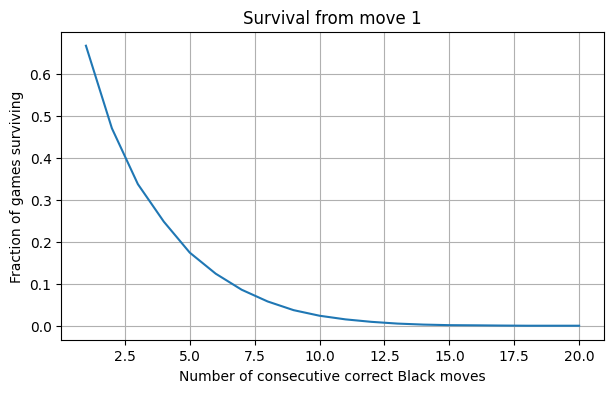

In [17]:
import matplotlib.pyplot as plt

def plot_survival(metrics, title):
    survival = metrics["survival"]

    plt.figure(figsize=(7, 4))
    plt.plot(range(1, len(survival) + 1), survival)
    plt.xlabel("Number of consecutive correct Black moves")
    plt.ylabel("Fraction of games surviving")
    plt.title(title)
    plt.grid(True)
    plt.savefig(RESULTS_DIR / "test_survival_curve.png", dpi=160, bbox_inches="tight")
    plt.show()

plot_survival(metrics, "Survival from move 1")


## Error inspection


In [18]:
errors = metrics["results"][metrics["results"]["correct_prefix"] < metrics["results"]["length"]]
errors[["white", "true_black", "pred_black", "correct_prefix", "length"]].head(10)

,white,true_black,pred_black,correct_prefix,length
0,e3 Qf3 e4 exd5 Bc4 Nc3 Ne4 Bxe6 Nxf6+ Qh5+ Qg4...,d5 e5 Nf6 Nxd5 Nf6 c6 Be6 fxe6 Qxf6 g6 Nd7 Bc5...,e5 Nf6 d5 Nxd5 Nf6 c6 Be6 fxe6 Qxf6 g6 Bg7 Nd7...,0,24
1,d4 c4 Nc3 e4 Bd3 Nge2 O-O f4 a3 fxe5 d5 Nxd4 N...,d6 e6 Nf6 g6 Bg7 O-O Nc6 Re8 e5 dxe5 Nd4 exd4 ...,g6 Bg7 d6 c6 Nf6 O-O Nbd7 Re8 e5 dxe5 Nd4 exd4...,0,36
2,d4 c4 Nc3 Nf3 Bg5 e3 Bd3 O-O Bxc4 Bd3 a3 Rc1 N...,Nf6 g6 d5 Bg7 c6 O-O e6 dxc4 b5 a6 Bb7 Nbd7 Rc...,d5 e6 Nf6 c6 Be7 O-O Nbd7 dxc4 b5 a6 Bb7 Rc8 Q...,0,25
3,e4 Nf3 d4 dxe5 Qxd8+ Nxe5 c3 Nc4 Be3 Be2 Nbd2 ...,e5 Nc6 d6 dxe5 Nxd8 Bb4+ Bd6 Bc5 Ne6 Nf6 b5 Nx...,e5 d6 Bg4 dxe5 Kxd8 Bb4+ Bc5 f6 Ne7 b6 c5 bxc5...,1,27
4,e4 d3 Nd2 Ngf3 g3 Bg2 O-O Re1 b3 Bb2 c3 a3 b4 ...,b6 Bb7 Nf6 e6 Be7 h6 O-O d6 e5 Nbd7 c6 d5 dxe4...,b6 Bb7 e6 d6 Be7 Nf6 O-O Nbd7 e5 c6 d5 d4 e4 c...,2,48
5,e4 f4 Nf3 c3 e5 fxe5 d4 cxd4 Bb5 d5 Bxd7+ Nc3 ...,c5 d6 Nc6 Nf6 dxe5 Nd5 cxd4 Nb6 Bd7 Nb4 Qxd7 N...,c5 d6 Nc6 Nf6 dxe5 Nd5 cxd4 e6 Bd7 Nb4 Qxd7 Nx...,7,22
6,e4 Bc4 Nf3 O-O Bb5 Bxc6+ e5 d3 Bf4 Nc3 exf6 Bd...,c5 Nc6 e6 Nf6 d5 bxc6 Nd7 Be7 O-O f6 Bxf6 Rf7 ...,c5 Nc6 e6 d5 a6 bxc6 Ne7 Ng6 Be7 f6 Bxf6 Qc7 O...,3,31
7,e4 Nf3 c3 e5 d4 Bd3 Be3 Nbd2 Nc4 Qd2 b3 bxc4 B...,g6 Bg7 Nf6 e6 Ng8 Ne7 O-O Nec6 b6 Ba6 Bxc4 Na6...,g6 Bg7 Nf6 Ng8 e6 Ne7 O-O b6 Bb7 c5 c4 Nbc6 f5...,3,57
8,d4 Nc3 e4 Nf3 e5 Bg5 Bxe7 Qd2 a3 O-O-O b4 Qg5 ...,g6 Bg7 d6 e6 d5 Ne7 Qxe7 Nc6 a6 b5 Bd7 Qf8 Bh6...,Nf6 e6 Be7 d5 Nfd7 O-O Qxe7 Nc6 a6 b5 Bb7 f6 f...,0,21
9,e4 d4 d5 c4 Nc3 Qe2 exd5 Bd2 O-O-O a3 Ne4 f3 B...,b6 Bb7 g6 Bg7 c6 cxd5 Qc7 Qc5 Qb4 Qc5 Qc7 Qe5 ...,b6 Bb7 g6 Bg7 e6 exd5 Qe7+ Na6 Nb4 Na6 Qd8 Ne7...,4,22


## Experiment constraints

The model uses no external chess data and stays below six million trainable parameters. Model weights and original datasets are not included in this public portfolio copy. See the README for the verification summary and access limitations.


## Reproducibility note

Neural-network training can have nondeterministic behavior on GPUs. The saved measurements document one completed experiment.


## Model checkpoint reload verification

Checks that the persisted weights load into the same architecture and reproduce logits on a validation probe. The completed run reported maximum absolute difference `0.0`.


In [19]:
# Verify that the persisted Drive checkpoint reloads into the SAME architecture.
assert Path(BEST_WEIGHTS_PATH).is_file(), f"Missing checkpoint: {BEST_WEIGHTS_PATH}"
assert VOCAB_PATH.is_file(), f"Missing vocabulary: {VOCAB_PATH}"
assert CONFIG_PATH.is_file(), f"Missing model config: {CONFIG_PATH}"

verification_model = build_core_model()
verification_model.load_weights(BEST_WEIGHTS_PATH)

probe_encoder = tf.convert_to_tensor(x_valid_ids[:2], dtype=tf.int32)
probe_decoder = tf.convert_to_tensor(decoder_valid_ids[:2], dtype=tf.int32)
reference_logits = core_model((probe_encoder, probe_decoder), training=False).numpy()
reloaded_logits = verification_model((probe_encoder, probe_decoder), training=False).numpy()

maximum_difference = float(np.max(np.abs(reference_logits - reloaded_logits)))
print("Reload maximum absolute difference:", maximum_difference)
assert maximum_difference < 1e-5, "Reloaded checkpoint differs from in-memory model"
print("Saved artifacts:")
for p in [Path(BEST_WEIGHTS_PATH), TRAIN_LOG_PATH, VOCAB_PATH, CONFIG_PATH,
          ARTIFACTS_DIR / "inference_config.json", RESULTS_DIR / "test_metrics.json"]:
    print(" -", p, "present:", p.is_file())


Reload maximum absolute difference: 0.0
Saved artifacts:
 - /content/drive/MyDrive/chess_move_prediction/transformer_5x5_v1/weights/white_to_black_5x5_best.weights.h5 present: True
 - /content/drive/MyDrive/chess_move_prediction/transformer_5x5_v1/results/training_history.csv present: True
 - /content/drive/MyDrive/chess_move_prediction/transformer_5x5_v1/artifacts/joint_vocabulary.json present: True
 - /content/drive/MyDrive/chess_move_prediction/transformer_5x5_v1/artifacts/model_config.json present: True
 - /content/drive/MyDrive/chess_move_prediction/transformer_5x5_v1/artifacts/inference_config.json present: True
 - /content/drive/MyDrive/chess_move_prediction/transformer_5x5_v1/results/test_metrics.json present: True
